# Lecture 13 - Classification: Decision Trees, Random Forests, and SVM

External dataset used in the examples: Arzamasov, V. (2018). *Electrical Grid Stability Simulated Data*. UCI Machine Learning Repository. DOI: `10.24432/C5PG66`. Page: https://archive.ics.uci.edu/dataset/471/electrical+grid+stability+simulated+data

## Where this lesson fits

- We have covered KNN, logistic regression, and linear regression.
- This lesson covers classifiers with nonlinear boundaries and practical interpretability.
- Guiding problem: predict whether a simulated electrical grid is **stable** or **unstable**.
- Compare decision trees, random forests, and SVM using mathematical formulations and metrics.
- System: a four-node star network with a central producer and consumers.
- Task: binary classification of the `stabf` field: `stable` or `unstable`.

## Environment setup, data loading, and models

In [1]:
import urllib.request
import zipfile
from pathlib import Path

from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

DATA_DIR = Path("data")
FIG_DIR = Path("figures_lesson_13_dt_rf_svm")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

CSV_PATH = DATA_DIR / "Data_for_UCI_named.csv"
ZIP_PATH = DATA_DIR / "electrical_grid_stability_simulated_data.zip"
UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/471/electrical+grid+stability+simulated+data.zip"

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 220,
    "axes.grid": True,
    "grid.alpha": 0.25,
})


def savefig(name):
    path = FIG_DIR / name
    plt.tight_layout()
    plt.savefig(path, bbox_inches="tight")
    display(plt.gcf())
    plt.close()
    return path


if not CSV_PATH.exists():
    with urllib.request.urlopen(UCI_ZIP_URL, timeout=60) as response:
        ZIP_PATH.write_bytes(response.read())
    with zipfile.ZipFile(ZIP_PATH) as zf:
        member = [m for m in zf.namelist() if m.endswith(".csv")][0]
        CSV_PATH.write_bytes(zf.read(member))


df = pd.read_csv(CSV_PATH)

feature_cols = [c for c in df.columns if c not in ["stab", "stabf", "p1"]]
X = df[feature_cols]
y_text = df["stabf"]

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)
stable_label = int(label_encoder.transform(["stable"])[0])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

tree = DecisionTreeClassifier(max_depth=4, min_samples_leaf=30, random_state=42)
forest = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", C=10, gamma="scale", random_state=42)),
])

models = {
    "Decision tree": tree,
    "Random forest": forest,
    "SVM RBF": svm,
}

for model in models.values():
    model.fit(X_train, y_train)

df.head()

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable


## Predictors and target variable

- Predictors: $\tau_i$, $p_i$, and $g_i$ for consumer nodes.
- $\tau_i$: response time of node $i$.
- $p_i$: rated power consumed at node $i$.
- $g_i$: coefficient proportional to price elasticity.
- `stab`: continuous stability index; removed to prevent leakage.
- `stabf`: class label used for training: `stable`/`unstable`.

Figure used in the slides: class balance for `stable` and `unstable`.

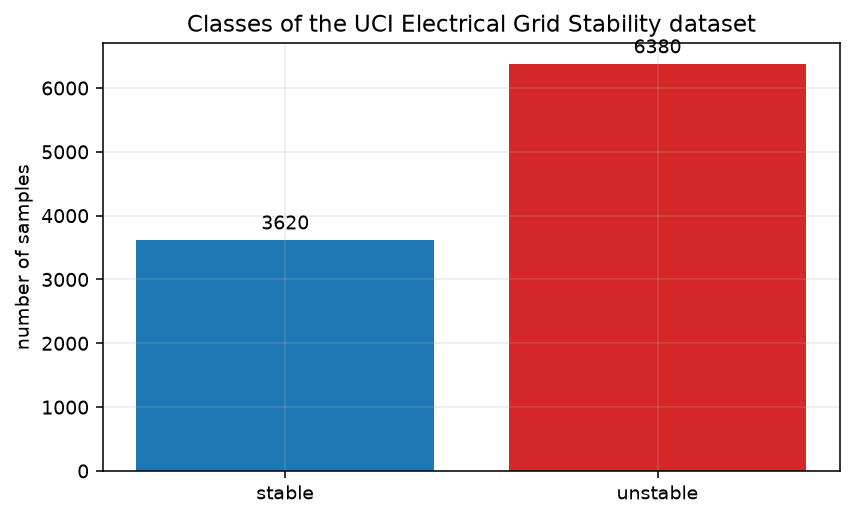

stabf
stable      3620
unstable    6380
Name: count, dtype: int64

In [2]:
counts = y_text.value_counts().reindex(["stable", "unstable"])
fig, ax = plt.subplots(figsize=(6.2, 3.8))
bars = ax.bar(["stable", "unstable"], counts.values, color=["#1f77b4", "#d62728"])
ax.set_title("Classes of the UCI Electrical Grid Stability dataset")
ax.set_ylabel("number of samples")
ax.bar_label(bars, padding=3)
savefig("01_class_balance.png")
counts

## What makes this problem interesting?

- The figure uses two original variables: `tau2` and `g2`.
- Stable and unstable points are mixed in this visualization.
- Therefore, a simple rule based on a single variable or a straight line is likely insufficient.
- We need models that combine multiple variables and capture interactions.

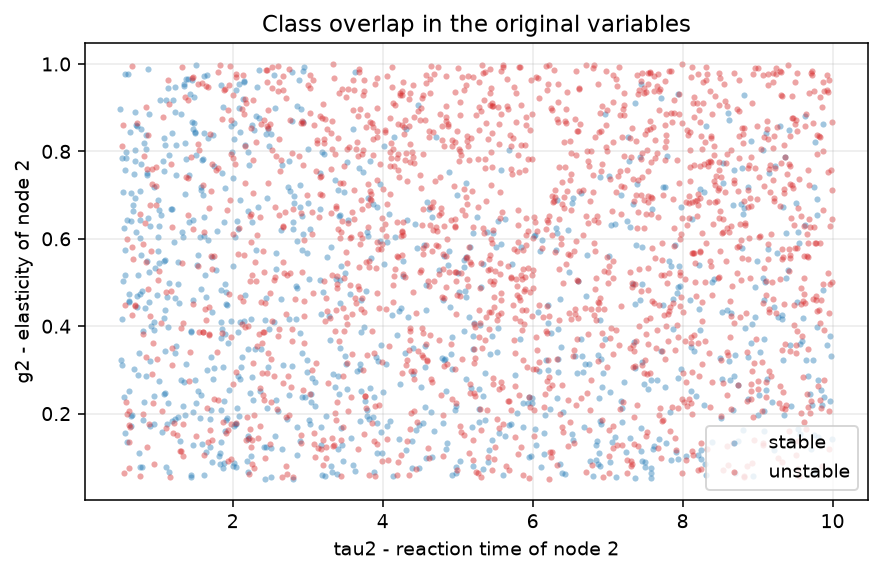

PosixPath('figures_lesson_13_dt_rf_svm/02_original_variables_classes.png')

In [3]:
sample = df.sample(n=2500, random_state=42)
fig, ax = plt.subplots(figsize=(6.4, 4.2))
colors = {"stable": "#1f77b4", "unstable": "#d62728"}
labels = {"stable": "stable", "unstable": "unstable"}
for cls, group in sample.groupby("stabf"):
    ax.scatter(
        group["tau2"], group["g2"], s=10, alpha=0.42,
        c=colors[cls], label=labels[cls], linewidths=0,
    )
ax.set_xlabel("tau2 - reaction time of node 2")
ax.set_ylabel("g2 - elasticity of node 2")
ax.set_title("Class overlap in the original variables")
ax.legend(frameon=True, loc="lower right")
savefig("02_original_variables_classes.png")

# Decision trees

## A tree as a sequence of questions

- Each internal node asks a question such as ``feature <= threshold?''.
- Each answer leads to another question or to a leaf, a terminal node that produces the prediction.
- The leaf predicts the most frequent class among the samples that reach it.

Conceptual example used in the slides:

```text
g2 <= c1?
├── yes:  tau3 <= c2?  -> stable / unstable
└── no:   g4 <= c3?    -> stable / unstable
```

## How does the tree choose a question?

For the electrical grid example:

- One sample is a grid simulation with values of $\tau_i$, $p_i$, and $g_i$.
- The classes are $k=$ `stable` and $k=$ `unstable`.
- Node $m$: a group of samples that reached the same point in the tree.
- $n_m$: number of samples in that node.
- $p_{mk}$: proportion of class $k$ in node $m$:

$$
p_{mk}=\frac{\text{number of samples of class }k\text{ in node }m}{n_m}.
$$

Idea: a good question creates more homogeneous groups, with nearly all samples `stable` or nearly all `unstable`.

## Impurity: the idea used by a tree

- Pure node: nearly all samples belong to the same class.
- Mixed node: many `stable` and `unstable` samples are together.
- By default, `scikit-learn` uses the Gini index:

$$
Gini(m)=1-\sum_{k=1}^K p_{mk}^2.
$$

- Gini is 0 for a pure node: all `stable` or all `unstable`.
- Gini is maximal when classes are evenly mixed: 50% `stable` and 50% `unstable`.
- Training: at each node, choose the feature and threshold that most reduce the impurity of the child nodes.

## First levels of the trained tree

Figure used in the slides showing the first levels of the trained tree.

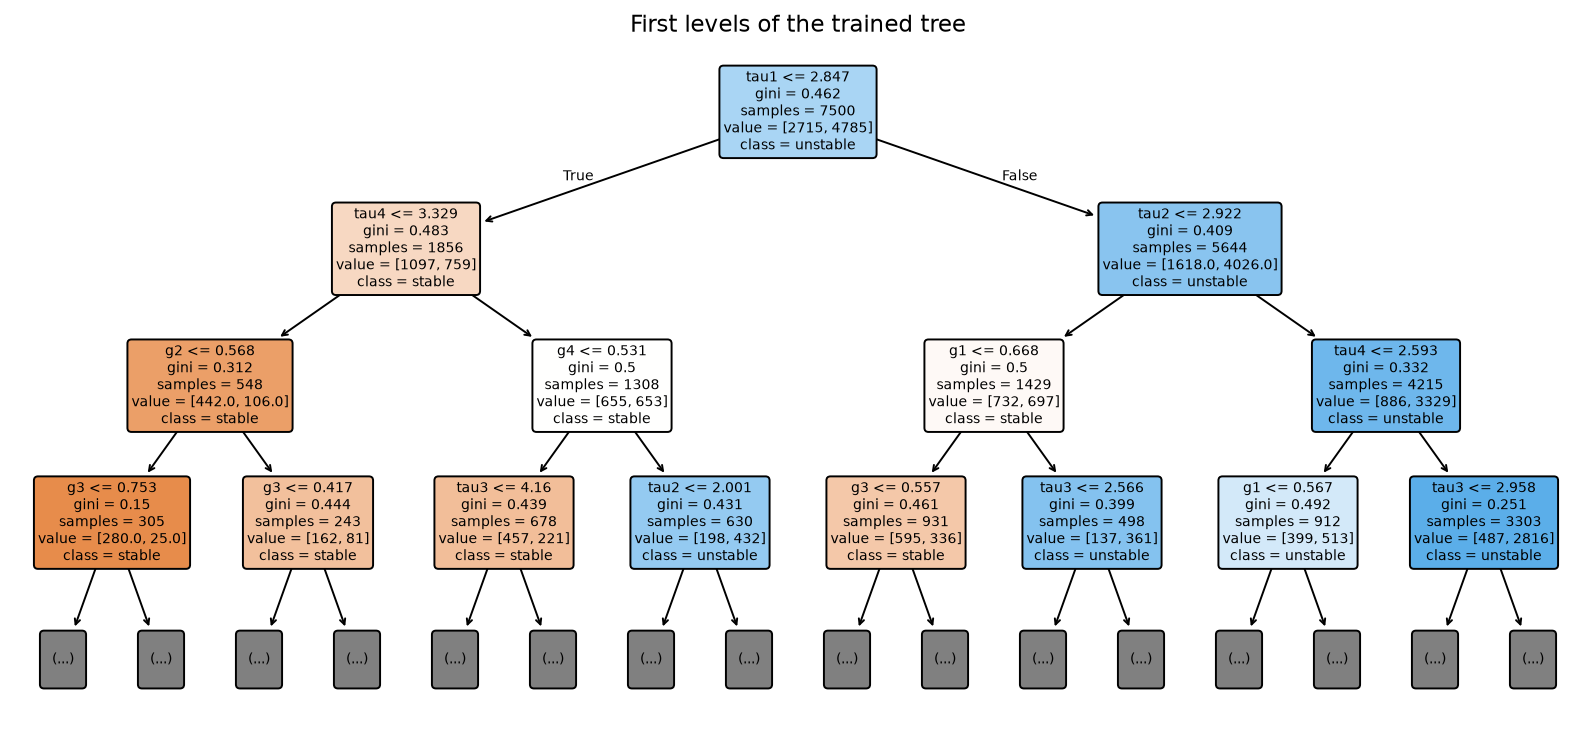

PosixPath('figures_lesson_13_dt_rf_svm/03_decision_tree.png')

In [4]:
fig, ax = plt.subplots(figsize=(11.5, 5.4))
plot_tree(
    tree,
    max_depth=3,
    feature_names=feature_cols,
    class_names=label_encoder.classes_,
    filled=True,
    rounded=True,
    impurity=True,
    fontsize=7,
    ax=ax,
)
ax.set_title("First levels of the trained tree")
savefig("03_decision_tree.png")

## Minimal pipeline for training a decision tree

The code below is the same minimal pipeline shown in the slides.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

dt = Pipeline([
    ("tree", DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=30,
        random_state=42))
])

dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)

Slide notes:

- `max_depth`: maximum depth; limits the sequence of questions.
- `min_samples_leaf`: minimum number of samples in each leaf.
- These can be selected by cross-validation, for example with `GridSearchCV`.
- `fit`: learns the questions; `predict`: returns `stable`/`unstable`.

# Random forests

## From a single tree to an ensemble

- A single tree can change substantially when the training set changes slightly: it has high variance.
- A random forest reduces this effect by training many different trees.
- Each tree uses the same logic: questions of the form `feature <= threshold`.
- Two sources of randomness help make the trees different:
  - **sampling with replacement**: some samples are repeated while others are left out;
  - **feature subsets**: only some features can be tested at each node.
- The final class is chosen by majority vote:

$$
\hat y = \operatorname{mode}\{h_1(x), h_2(x), \ldots, h_B(x)\}
$$

Here, $h_b(x)$ is the class predicted by tree $b$ for sample $x$.

## Random forest in `scikit-learn`

The code below is the same random forest pipeline shown in the slides.

In [6]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

Slide notes:

- `n_estimators=300`: trains 300 trees.
- `min_samples_leaf=3`: each leaf must contain at least 3 samples.
- `class_weight="balanced"`: gives greater weight to the less frequent class during training.
- `random_state=42`: fixes randomness to reproduce the result.
- `n_jobs=-1`: uses all available CPU cores.

# Support Vector Machines

## Linear SVM: maximum margin

For two classes, use $y_i \in \{-1,+1\}$. A linear SVM decides from the sign of:

$$
f(x)=w^Tx+b
$$

- If $f(x)>0$, it predicts one class; if $f(x)<0$, it predicts the other.
- The vector $w$ and scalar $b$ are learned during training.

## RBF kernel: nonlinear boundaries

With a kernel, the decision is no longer written directly as $w^Tx+b$ but as:

$$
f(x)=\sum_{i \in SV}\alpha_i y_i K(x_i,x)+b
$$

- $x$: sample to classify.
- $x_i$: training sample that became a support vector.
- $y_i$: known true class of support vector $x_i$.
- $K(x_i,x)$: similarity between $x_i$ and $x$.
- $\alpha_i$: weight learned during training.

For the RBF kernel:

$$
K(x_i,x)=\exp(-\gamma\lVert x_i-x\rVert^2)
$$

Thus:

$$
f(x)=\sum_{i \in SV}\alpha_i y_i\exp(-\gamma\lVert x_i-x\rVert^2)+b
$$

- Classification follows the sign of $f(x)$.
- The decision boundary is given by $f(x)=0$.
- Because RBF depends on distances, feature scaling is essential.

## 2D SVM: two features and one class

- Each point is a sample: $x=[x_1,x_2]$.
- $x_1$: normalized voltage deviation.
- $x_2$: normalized load variation.
- $y$: true class, such as `acceptable` or `risk`.
- The SVM learns a rule $\hat y=f(x_1,x_2)$.

Figure used in the slides: a synthetic 2D example contextualized in electrical grid operation.

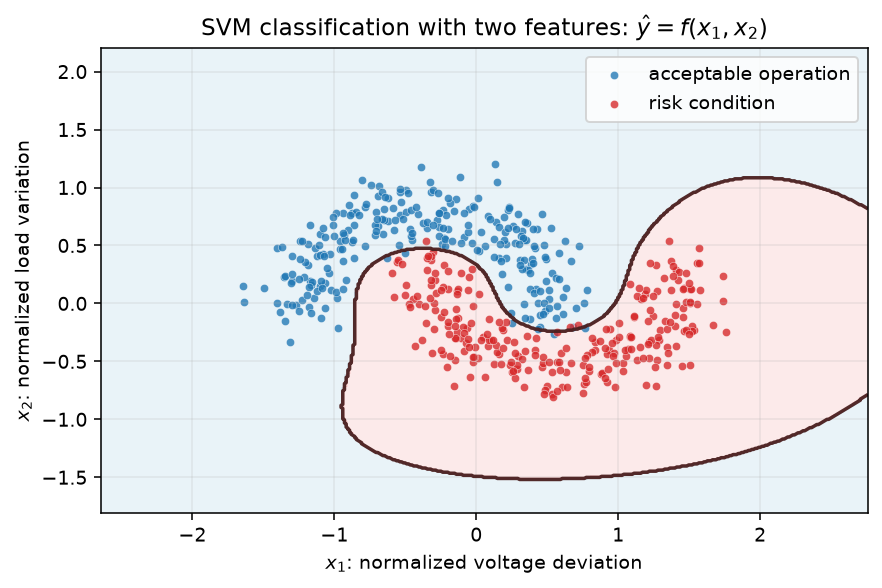

In [7]:
# Synthetic example: two operating regions not separable by a straight line.
# Model input: x = [x1, x2].
# x1 = normalized voltage deviation; x2 = normalized load variation.
# y = 0 indicates acceptable operation; y = 1 indicates a risk condition.
X_svm2d, y_svm2d = make_moons(n_samples=520, noise=0.18, random_state=7)
X_svm2d[:, 0] = 0.9 * X_svm2d[:, 0] - 0.35
X_svm2d[:, 1] = 0.9 * X_svm2d[:, 1] - 0.10

svm_2d = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", C=10, gamma="scale"))
])
svm_2d.fit(X_svm2d, y_svm2d)

fig, ax = plt.subplots(figsize=(6.4, 4.3))
region_cmap = ListedColormap(["#9ecae1", "#f4a3a3"])
DecisionBoundaryDisplay.from_estimator(
    svm_2d,
    X_svm2d,
    response_method="predict",
    alpha=0.22,
    cmap=region_cmap,
    grid_resolution=250,
    ax=ax,
)

x_min, x_max = ax.get_xlim()
y_min, y_max = ax.get_ylim()
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 450), np.linspace(y_min, y_max, 450))
zz = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
ax.contour(xx, yy, zz, levels=[0.5], colors="#4a1f1f", linewidths=1.8, alpha=0.95)

labels = {0: "acceptable operation", 1: "risk condition"}
colors = {0: "#1f77b4", 1: "#d62728"}
for cls in [0, 1]:
    idx = y_svm2d == cls
    ax.scatter(
        X_svm2d[idx, 0],
        X_svm2d[idx, 1],
        s=18,
        alpha=0.78,
        c=colors[cls],
        label=labels[cls],
        edgecolor="white",
        linewidth=0.25,
    )

ax.set_xlabel("$x_1$: normalized voltage deviation")
ax.set_ylabel("$x_2$: normalized load variation")
ax.set_title("SVM classification with two features: $\\hat y=f(x_1,x_2)$")
ax.legend(frameon=True, loc="upper right")
ax.grid(alpha=0.22)
plt.tight_layout()
plt.savefig(FIG_DIR / "09_2d_svm_engineering.png", bbox_inches="tight", dpi=220)
display(fig)
plt.close()

## SVM in `scikit-learn`

The code below is the same SVM pipeline shown in the slides.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", C=10, gamma="scale",
                random_state=42))
])
svm.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['tau1','tau2','tau3',...,'g2','g3','g4']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Slide notes:

- `StandardScaler`: puts variables on comparable scales.
- `kernel="rbf"`: allows a nonlinear boundary.
- `C=10`: controls regularization; larger values penalize training errors more and reduce effective regularization.
- `gamma="scale"`: automatically sets the RBF scale.
- `random_state=42`: fixes internal randomness.
- `Pipeline` prevents data leakage: the scaler is fitted on training data only.

# Experimental comparison

## Test-set results

Precision, recall, and F1 were calculated for the `stable` class.

In [9]:
metrics = []
for name, model in models.items():
    pred = model.predict(X_test)
    metrics.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, pos_label=stable_label),
        "Recall": recall_score(y_test, pred, pos_label=stable_label),
        "F1": f1_score(y_test, pred, pos_label=stable_label),
    })

metrics_df = pd.DataFrame(metrics)
metrics_df.round(3)

,Model,Accuracy,Precision,Recall,F1
0,Decision tree,0.767,0.706,0.612,0.656
1,Random forest,0.928,0.881,0.927,0.904
2,SVM RBF,0.972,0.964,0.959,0.962


Interpretation presented in the slides:

- The decision tree is the simplest model but misses many `stable` cases.
- The random forest improves all metrics over a single tree.
- The RBF SVM achieved the best performance on this dataset.

## Confusion matrices

Figure used in the slides showing the confusion matrices for all three models.

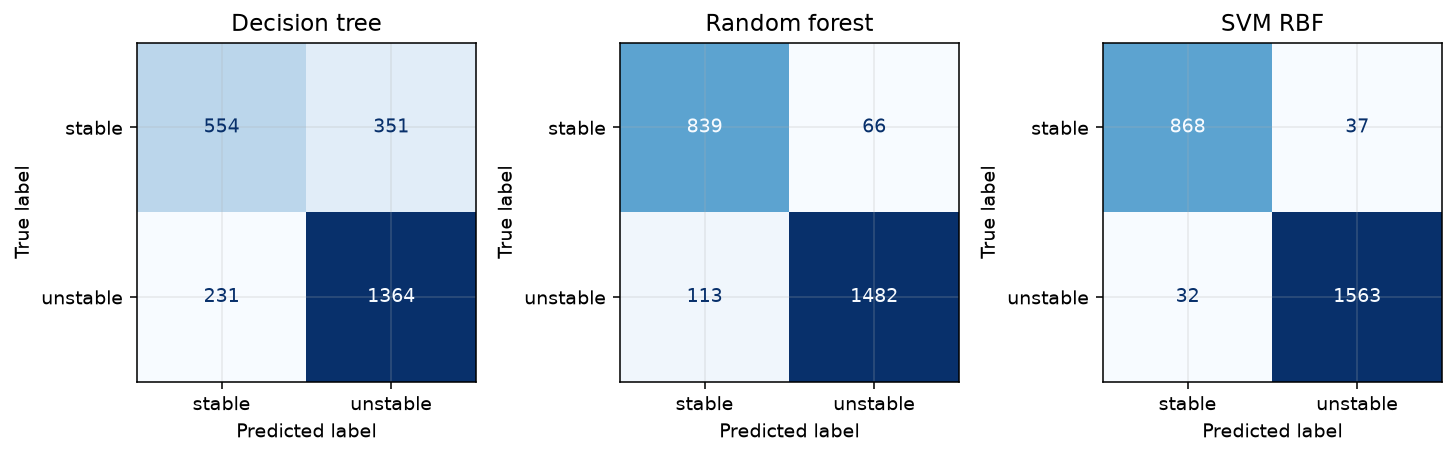

PosixPath('figures_lesson_13_dt_rf_svm/05_confusion_matrices.png')

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        model.predict(X_test),
        display_labels=label_encoder.classes_,
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name)
savefig("05_confusion_matrices.png")

## Model interpretation

- Decision tree: more interpretable and useful for discussing rules, but it may have high variance.
- Random forest: often performs better on tabular data and handles nonlinear interactions robustly.
- RBF SVM: strong, smooth boundaries, but less transparent and sensitive to scaling and hyperparameters.
- In engineering applications, metrics should reflect operational risk: a false stable prediction may be more serious than a false unstable prediction.
- Good practices: split training/test data before tuning, use cross-validation, and document removed features.

## Suggested exercises

1. Train decision trees with `max_depth` from 1 to 15 and plot training versus test performance.
2. Replace the RBF kernel with linear and polynomial kernels. Compare F1, precision, recall, and training time.
3. Define a metric that penalizes classifying an unstable grid as stable more heavily.

## References

- GRUS, Joel. *Data Science do Zero: Noções Fundamentais com Python*. 2nd ed. Alta Books, 2020.
- Arzamasov, V. (2018). *Electrical Grid Stability Simulated Data* [Dataset]. UCI Machine Learning Repository. DOI: `10.24432/C5PG66`.
- Pedregosa et al. *Scikit-learn: Machine Learning in Python*. JMLR, 2011.